# Global Solution 2026.2 · CitizenTech
## Modelagem Matemática e Computacional
### Mobilidade Urbana Inteligente: Modelagem Matemática para a Gestão do Transporte Público

**Integrantes:**

- Gabriel Barbosa Furin · RM 572941
- Lucas Kiodi Moraca · RM 571004
- Renan Fracalossi Mano da Silva · RM 569610

**Disciplina:** Modelagem Matemática e Computacional · 1º ano de Ciência da Computação · FIAP

---

**Projeto de contexto:** *Plantão Enchente* (Citizen Assist AI). Em enchentes e temporais, a frota de ônibus é um recurso crítico para evacuação e retorno. Este notebook desenvolve o modelo-base de **distribuição e redistribuição de frota** que o assistente usará como motor de cálculo de mobilidade.

**Organização do notebook**

| Parte | Conteúdo |
|---|---|
| Etapa 1 | Recuperar a distribuição atual da frota (sistema linear, unicidade, solução em Python, verificação) |
| Etapa 2 | Estimar necessidade por região, diagnosticar desequilíbrios, propor a política e representá-la como transformação linear |
| Extras | Gráficos, indicadores e testes automatizados |

> Os dados do enunciado são **hipotéticos** e simplificam a operação real.

In [1]:
import math
from itertools import product

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.optimize import linprog

np.set_printoptions(suppress=True, precision=4)
REGIOES = ["Norte", "Sul", "Leste", "Oeste"]

---
# ETAPA 1 · Diagnóstico e modelagem da situação atual

## 1(a) Variáveis do problema

Sejam as quantidades de ônibus alocadas em cada centro operacional:

- $N$: ônibus da região **Norte**
- $S$: ônibus da região **Sul**
- $L$: ônibus da região **Leste**
- $O$: ônibus da região **Oeste**

Pelo enunciado, $N, S, L, O \in \mathbb{Z}_{\ge 0}$ (inteiros não negativos).

## 1(b) Modelo matemático

Os registros do Relatório I viram equações lineares:

| Registro operacional | Equação |
|---|---|
| Frota regular de 72 ônibus | $N + S + L + O = 72$ |
| Norte + Oeste + dobro do Sul = 76 | $N + 2S + O = 76$ |
| Sul + dobro do Leste = 52 | $S + 2L = 52$ |
| Norte + Leste + dobro do Oeste = 76 | $N + L + 2O = 76$ |

## 1(c) Representação matricial

Com $\mathbf{x} = (N, S, L, O)^T$, o sistema é $A\mathbf{x} = \mathbf{b}$:

$$
\underbrace{\begin{pmatrix}
1 & 1 & 1 & 1\\
1 & 2 & 0 & 1\\
0 & 1 & 2 & 0\\
1 & 0 & 1 & 2
\end{pmatrix}}_{A}
\underbrace{\begin{pmatrix} N\\ S\\ L\\ O \end{pmatrix}}_{\mathbf{x}}
=
\underbrace{\begin{pmatrix} 72\\ 76\\ 52\\ 76 \end{pmatrix}}_{\mathbf{b}}
$$

In [2]:
A = sp.Matrix([[1, 1, 1, 1],
               [1, 2, 0, 1],
               [0, 1, 2, 0],
               [1, 0, 1, 2]])
b = sp.Matrix([72, 76, 52, 76])

sp.pprint(A)
print("b =", list(b))

⎡1  1  1  1⎤
⎢          ⎥
⎢1  2  0  1⎥
⎢          ⎥
⎢0  1  2  0⎥
⎢          ⎥
⎣1  0  1  2⎦
b = [72, 76, 52, 76]


## 1(d) A solução é única? Justificativa com Álgebra Linear

Temos **4 equações e 4 incógnitas**. Pelo **Teorema de Rouché-Capelli**, um sistema $A\mathbf{x}=\mathbf{b}$ com $n$ incógnitas:

- é **incompatível** se $\operatorname{posto}(A) < \operatorname{posto}([A\,|\,\mathbf{b}])$;
- é **compatível determinado** (solução única) se $\operatorname{posto}(A) = \operatorname{posto}([A\,|\,\mathbf{b}]) = n$;
- é **compatível indeterminado** se os postos são iguais mas menores que $n$.

Como $A$ é quadrada, $\operatorname{posto}(A)=4 \iff \det(A)\neq 0 \iff A$ é invertível $\iff$ $\mathcal{N}(A)=\{\mathbf{0}\}$. Nesse caso a solução é única para **qualquer** $\mathbf{b}$: $\mathbf{x}=A^{-1}\mathbf{b}$.

**Cálculo do determinante** (expansão de cofatores pela terceira linha, que tem dois zeros):

$$
\det A = 1\cdot(-1)^{3+2}\det\begin{pmatrix}1&1&1\\1&0&1\\1&1&2\end{pmatrix} + 2\cdot(-1)^{3+3}\det\begin{pmatrix}1&1&1\\1&2&1\\1&0&2\end{pmatrix}
$$

Esses dois determinantes $3\times3$ valem $-1$ e $1$, logo $\det A = -(-1) + 2\cdot 1 = 3$. O código abaixo confere o valor por cálculo simbólico exato.

In [3]:
det_A = A.det()
aumentada = A.row_join(b)

print("det(A)                  =", det_A)
print("posto(A)                =", A.rank())
print("posto([A | b])          =", aumentada.rank())
print("nº de incógnitas        =", A.shape[1])
print("nulidade (dim. núcleo)  =", A.shape[1] - A.rank())
print("núcleo de A             =", A.nullspace())

if A.rank() == aumentada.rank() == A.shape[1]:
    print("\n=> Sistema compatível determinado: SOLUÇÃO ÚNICA (Rouché-Capelli).")

det(A)                  = 3
posto(A)                = 4
posto([A | b])          = 4
nº de incógnitas        = 4
nulidade (dim. núcleo)  = 0
núcleo de A             = []

=> Sistema compatível determinado: SOLUÇÃO ÚNICA (Rouché-Capelli).


**Conclusão (d):** $\det A = 3 \neq 0$, $\operatorname{posto}(A)=\operatorname{posto}([A|\mathbf{b}])=4$ e o núcleo é trivial. Logo os registros consolidados **determinam uma única distribuição** de veículos. Não há ambiguidade a resolver com outras informações.

### Resolução à mão (eliminação), para conferir o resultado do código

Subtraindo a 1ª equação da 2ª: $S - L = 4 \Rightarrow S = L + 4$.
Substituindo na 3ª: $(L+4) + 2L = 52 \Rightarrow L = 16$ e $S = 20$.
Da 1ª: $N + O = 72 - 36 = 36$. Da 4ª: $N + 2O = 60$. Subtraindo: $O = 24$ e $N = 12$.

## 1(e) Resolução computacional em Python

Resolvemos de três formas independentes: **numérica** (`numpy`), **simbólica exata** (`sympy`) e por **escalonamento de Gauss-Jordan** (forma escalonada reduzida).

In [4]:
A_np = np.array(A.tolist(), dtype=float)
b_np = np.array(b.tolist(), dtype=float).ravel()

# 1) numérica
x_num = np.linalg.solve(A_np, b_np)

# 2) simbólica exata
x_sym = A.LUsolve(b)

# 3) Gauss-Jordan
rref, pivos = aumentada.rref()

print("numpy.linalg.solve :", x_num)
print("sympy (exato)      :", list(x_sym))
print("pivôs              :", pivos)
print("\nForma escalonada reduzida de [A | b]:")
sp.pprint(rref)

x_atual = np.array([int(v) for v in x_sym])   # (N, S, L, O) inteiros
print("\nDistribuição ATUAL da frota:")
for r, v in zip(REGIOES, x_atual):
    print(f"  {r:<6}: {v:>2} ônibus")
print(f"  Total : {x_atual.sum()} ônibus")

numpy.linalg.solve : [12. 20. 16. 24.]
sympy (exato)      : [12, 20, 16, 24]
pivôs              : (0, 1, 2, 3)

Forma escalonada reduzida de [A | b]:
⎡1  0  0  0  12⎤
⎢              ⎥
⎢0  1  0  0  20⎥
⎢              ⎥
⎢0  0  1  0  16⎥
⎢              ⎥
⎣0  0  0  1  24⎦

Distribuição ATUAL da frota:
  Norte : 12 ônibus
  Sul   : 20 ônibus
  Leste : 16 ônibus
  Oeste : 24 ônibus
  Total : 72 ônibus


## 1(f) Verificação: a solução satisfaz todos os registros?

In [5]:
registros = [
    ("Frota total = 72",                 lambda N,S,L,O: N + S + L + O,   72),
    ("Norte + Oeste + 2·Sul = 76",       lambda N,S,L,O: N + O + 2*S,     76),
    ("Sul + 2·Leste = 52",               lambda N,S,L,O: S + 2*L,         52),
    ("Norte + Leste + 2·Oeste = 76",     lambda N,S,L,O: N + L + 2*O,     76),
]
N, S, L, O = x_atual
tudo_ok = True
for nome, f, esperado in registros:
    obtido = f(N, S, L, O)
    ok = obtido == esperado
    tudo_ok &= ok
    print(f"{'OK ' if ok else 'ERRO'} | {nome:<30} -> obtido {obtido:>3} | esperado {esperado:>3}")

print("\nResíduo A·x - b =", A_np @ x_atual - b_np)
print("Todos inteiros e não negativos?", bool(np.all(x_atual >= 0)))
assert tudo_ok and np.all(x_atual >= 0)

OK  | Frota total = 72               -> obtido  72 | esperado  72
OK  | Norte + Oeste + 2·Sul = 76     -> obtido  76 | esperado  76
OK  | Sul + 2·Leste = 52             -> obtido  52 | esperado  52
OK  | Norte + Leste + 2·Oeste = 76   -> obtido  76 | esperado  76

Resíduo A·x - b = [0. 0. 0. 0.]
Todos inteiros e não negativos? True


---
# ETAPA 2 · Política de redistribuição da frota

## 2(a) Necessidade de ônibus por região

Cada passageiro ocupa uma vaga e cada ônibus oferece 40 vagas no período de pico. Para atender toda a demanda, a região $i$ precisa de

$$
n_i = \left\lceil \frac{\text{passageiros}_i}{40} \right\rceil
$$

(arredondamento para cima, pois não existe fração de ônibus e queremos atender todos os passageiros).

In [6]:
passageiros = np.array([560, 760, 720, 840])
capacidade  = 40

necessario = np.array([math.ceil(p / capacidade) for p in passageiros])

print(f"{'Região':<8}{'Demanda':>9}{'Necessário':>12}{'Atual':>8}")
for r, p, n, a in zip(REGIOES, passageiros, necessario, x_atual):
    print(f"{r:<8}{p:>9}{n:>12}{a:>8}")
print(f"{'Total':<8}{passageiros.sum():>9}{necessario.sum():>12}{x_atual.sum():>8}")

Região    Demanda  Necessário   Atual
Norte         560          14      12
Sul           760          19      20
Leste         720          18      16
Oeste         840          21      24
Total        2880          72      72


**Observação importante:** a necessidade total é exatamente **72 ônibus**, igual à frota. Ou seja, a frota **basta** para atender a demanda, mas está **mal distribuída**. É um problema de redistribuição, não de ampliação (o enunciado, aliás, proíbe ampliar a frota).

## 2(b) Desequilíbrios

Definimos o **saldo** $d_i = x_i - n_i$ (ônibus atuais menos necessários):

- $d_i > 0$: **excedente** (a região tem ônibus sobrando);
- $d_i < 0$: **déficit** (a região precisa receber ônibus).

In [7]:
saldo = x_atual - necessario
capac_atual = x_atual * capacidade
atendidos_antes = np.minimum(passageiros, capac_atual)
nao_atendidos_antes = passageiros - atendidos_antes
ocupacao_antes = passageiros / capac_atual

print(f"{'Região':<8}{'Saldo':>7}{'Situação':>12}{'Ocupação':>11}{'Sem vaga':>10}")
for r, s, oc, na in zip(REGIOES, saldo, ocupacao_antes, nao_atendidos_antes):
    sit = "excedente" if s > 0 else ("déficit" if s < 0 else "equilibrada")
    print(f"{r:<8}{s:>+7}{sit:>12}{oc:>10.1%}{na:>10}")

print("\nPassageiros sem vaga (total):", nao_atendidos_antes.sum())
print("Ônibus em excedente (total)  :", saldo[saldo > 0].sum())
print("Ônibus em déficit (total)    :", -saldo[saldo < 0].sum())

Região    Saldo    Situação   Ocupação  Sem vaga
Norte        -2     déficit    116.7%        80
Sul          +1   excedente     95.0%         0
Leste        -2     déficit    112.5%        80
Oeste        +3   excedente     87.5%         0

Passageiros sem vaga (total): 160
Ônibus em excedente (total)  : 4
Ônibus em déficit (total)    : 4


**Diagnóstico:**

- **Norte** e **Leste** estão em **déficit de 2 ônibus cada** (ocupação acima de 100%: há passageiros sem vaga).
- **Sul** tem **1 ônibus sobrando** e **Oeste** tem **3 sobrando**.
- Total em excedente = total em déficit = **4 ônibus**. Esse é o **mínimo de ônibus que precisam trocar de região** para equilibrar o sistema (≈ 5,6% da frota).

## 2(c) Política de redistribuição e critérios

**Política proposta: "doar o excedente, só a quem tem déficit".**

1. **Conservação:** o total de 72 ônibus não muda (exigência da prefeitura).
2. **Compartilhamento:** apenas regiões com **excedente doam**, e apenas regiões com **déficit recebem**. Regiões equilibradas não participam.
3. **Mínimo de movimentação:** movem-se exatamente 4 ônibus, que é o limite inferior possível.
4. **Fluxos inteiros:** cada transferência é um número inteiro de ônibus.
5. **Proximidade (critério de desempate):** o enunciado não informa distâncias. Adotamos a hipótese simplificada de que os centros estão dispostos como os pontos cardeais, de modo que regiões **adjacentes** (ex.: Sul-Leste) têm custo de deslocamento 1 e regiões **opostas** (Norte-Sul, Leste-Oeste) têm custo 2. Entre as distribuições possíveis, escolhemos a de **menor custo total** de deslocamento.

Como as transferências formam um **problema de transporte**, a matriz de custos é ajustável: se a prefeitura tiver distâncias reais, basta trocar `custo` abaixo e a política é recalculada.

In [8]:
# Custo de deslocamento (hipótese): adjacente = 1, oposto = 2. Ordem: Norte, Sul, Leste, Oeste
oposto = {(0, 1), (1, 0), (2, 3), (3, 2)}
custo = np.array([[0 if i == j else (2 if (i, j) in oposto else 1) for j in range(4)]
                  for i in range(4)])
print("Matriz de custo (origem i -> destino j):")
print(custo)

doadores    = [i for i in range(4) if saldo[i] > 0]
receptores  = [j for j in range(4) if saldo[j] < 0]
print("\nDoadores  :", {REGIOES[i]: int(saldo[i]) for i in doadores})
print("Receptores:", {REGIOES[j]: int(-saldo[j]) for j in receptores})

# Problema de transporte: min sum c_ij f_ij  s.t.  sum_j f_ij = excedente_i ; sum_i f_ij = déficit_j ; f >= 0
pares = [(i, j) for i in doadores for j in receptores]
c = [custo[i, j] for i, j in pares]
A_eq, b_eq = [], []
for i in doadores:
    A_eq.append([1 if p[0] == i else 0 for p in pares]); b_eq.append(saldo[i])
for j in receptores:
    A_eq.append([1 if p[1] == j else 0 for p in pares]); b_eq.append(-saldo[j])

res = linprog(c, A_eq=A_eq, b_eq=b_eq, bounds=[(0, None)] * len(pares), method="highs-ds")
fluxo = {p: int(round(v)) for p, v in zip(pares, res.x)}

print("\nPolítica ótima (nº de ônibus a transferir):")
for (i, j), q in fluxo.items():
    if q:
        print(f"  {REGIOES[i]:<6} -> {REGIOES[j]:<6}: {q} ônibus  (custo unitário {custo[i, j]})")
print("Custo total:", int(round(res.fun)))
assert np.allclose(res.x, np.round(res.x)), "fluxos deveriam ser inteiros"

Matriz de custo (origem i -> destino j):
[[0 2 1 1]
 [2 0 1 1]
 [1 1 0 2]
 [1 1 2 0]]

Doadores  : {'Sul': 1, 'Oeste': 3}
Receptores: {'Norte': 2, 'Leste': 2}

Política ótima (nº de ônibus a transferir):
  Sul    -> Leste : 1 ônibus  (custo unitário 1)
  Oeste  -> Norte : 2 ônibus  (custo unitário 1)
  Oeste  -> Leste : 1 ônibus  (custo unitário 2)
Custo total: 5


In [9]:
# Conferência por enumeração: todas as políticas inteiras possíveis e seus custos
solucoes = []
for valores in product(range(0, 4), repeat=len(pares)):
    f = dict(zip(pares, valores))
    ok_doa = all(sum(f[(i, j)] for j in receptores) == saldo[i] for i in doadores)
    ok_rec = all(sum(f[(i, j)] for i in doadores) == -saldo[j] for j in receptores)
    if ok_doa and ok_rec:
        solucoes.append((sum(custo[i, j] * f[(i, j)] for i, j in pares), f))

print(f"{len(solucoes)} políticas inteiras viáveis (todas movem 4 ônibus):")
for cst, f in sorted(solucoes, key=lambda t: t[0]):
    desc = ", ".join(f"{REGIOES[i]}->{REGIOES[j]}: {q}" for (i, j), q in f.items() if q)
    print(f"  custo {cst} | {desc}")

2 políticas inteiras viáveis (todas movem 4 ônibus):
  custo 5 | Sul->Leste: 1, Oeste->Norte: 2, Oeste->Leste: 1
  custo 7 | Sul->Norte: 1, Oeste->Norte: 1, Oeste->Leste: 2


A política escolhida é a de **menor custo** (custo 5): **Sul→Leste: 1**, **Oeste→Norte: 2**, **Oeste→Leste: 1**. A outra alternativa viável custa 7 (envolve mais deslocamentos entre regiões opostas).

## 2(d) Representação como transformação linear

Seja $\mathbf{x}=(N,S,L,O)^T$ a distribuição atual e $T:\mathbb{R}^4\to\mathbb{R}^4$ a transformação que leva à nova distribuição $\mathbf{x}'$:

$$
T(\mathbf{x}) = A_T\,\mathbf{x}
$$

Toda transformação definida por uma matriz é linear, pois, para $\mathbf{u},\mathbf{v}\in\mathbb{R}^4$ e $\alpha\in\mathbb{R}$:

$$
T(\mathbf{u}+\mathbf{v}) = A_T(\mathbf{u}+\mathbf{v}) = A_T\mathbf{u}+A_T\mathbf{v} = T(\mathbf{u})+T(\mathbf{v}),
\qquad
T(\alpha\mathbf{u}) = A_T(\alpha\mathbf{u}) = \alpha\,T(\mathbf{u}).
$$

**Interpretação como fração da frota.** Cada centro $j$ doa uma **fração** da sua frota atual e mantém o restante. Assim o coeficiente $a_{ij}$ de $A_T$ é a **fração da frota do centro $j$ que passa a ficar no centro $i$**.

## 2(e) Construção da matriz e significado dos coeficientes

Fluxos escolhidos ($q_{j\to i}$ ônibus) e as frações correspondentes, dividindo pela frota atual do doador:

| Transferência | Ônibus | Fração da frota do doador |
|---|---|---|
| Sul → Leste | 1 | $1/20$ (Sul tem 20) |
| Oeste → Norte | 2 | $2/24 = 1/12$ (Oeste tem 24) |
| Oeste → Leste | 1 | $1/24$ |

In [10]:
R = sp.Rational
idx = {r: k for k, r in enumerate(REGIOES)}
N_, S_, L_, O_ = (idx[r] for r in REGIOES)

# fluxos (origem j -> destino i) em ônibus
transf = {(S_, L_): 1, (O_, N_): 2, (O_, L_): 1}
assert transf == {(i, j): q for (i, j), q in fluxo.items() if q}

A_T = sp.zeros(4, 4)
for j in range(4):
    enviados = sum(q for (o, d), q in transf.items() if o == j)
    A_T[j, j] = R(int(x_atual[j]) - enviados, int(x_atual[j]))       # fração mantida
for (o, d), q in transf.items():
    A_T[d, o] = R(q, int(x_atual[o]))                                # fração enviada de o para d

print("Matriz da transformação A_T  (colunas = origem, linhas = destino; ordem N, S, L, O):")
sp.pprint(A_T)
print()
sp.pprint(A_T.applyfunc(lambda v: sp.Float(v, 4)))

Matriz da transformação A_T  (colunas = origem, linhas = destino; ordem N, S, L, O):
⎡1   0    0  1/12⎤
⎢                ⎥
⎢    19          ⎥
⎢0   ──   0   0  ⎥
⎢    20          ⎥
⎢                ⎥
⎢0  1/20  1  1/24⎥
⎢                ⎥
⎣0   0    0  7/8 ⎦

⎡1.0  0.0   0.0  0.08333⎤
⎢                       ⎥
⎢0.0  0.95  0.0    0.0  ⎥
⎢                       ⎥
⎢0.0  0.05  1.0  0.04167⎥
⎢                       ⎥
⎣0.0  0.0   0.0   0.875 ⎦


$$
A_T=\begin{pmatrix}
1 & 0 & 0 & \tfrac{1}{12}\\[2pt]
0 & \tfrac{19}{20} & 0 & 0\\[2pt]
0 & \tfrac{1}{20} & 1 & \tfrac{1}{24}\\[2pt]
0 & 0 & 0 & \tfrac{7}{8}
\end{pmatrix}
$$

**Como ler a matriz** (coluna = de onde sai, linha = para onde vai):

| Coeficiente | Valor | Significado |
|---|---|---|
| $a_{NN}$ | $1$ | Norte mantém 100% da frota própria (só recebe) |
| $a_{SS}$ | $19/20$ | Sul mantém 95% e doa 5% (1 ônibus) |
| $a_{LL}$ | $1$ | Leste mantém 100% (só recebe) |
| $a_{OO}$ | $7/8$ | Oeste mantém 87,5% e doa 12,5% (3 ônibus) |
| $a_{LS}$ | $1/20$ | 5% da frota do **Sul** vai para o **Leste** |
| $a_{NO}$ | $1/12$ | ≈8,3% da frota do **Oeste** vai para o **Norte** |
| $a_{LO}$ | $1/24$ | ≈4,2% da frota do **Oeste** vai para o **Leste** |
| demais | $0$ | sem transferência |

Cada **coluna soma 1**: tudo que um centro tem é ou mantido ou enviado. Isso é a chave da prova de conservação.

### Aplicando a transformação

In [11]:
x_vec = sp.Matrix([int(v) for v in x_atual])
x_novo = A_T * x_vec
print("x  (antes) =", list(x_vec))
print("x' (depois) =", list(x_novo))
print("necessário  =", [int(v) for v in necessario])
assert list(x_novo) == [int(v) for v in necessario], "a política não zera os desequilíbrios!"
print("\nA nova distribuição coincide exatamente com a necessidade de cada região.")

x  (antes) = [12, 20, 16, 24]
x' (depois) = [14, 19, 18, 21]
necessário  = [14, 19, 18, 21]

A nova distribuição coincide exatamente com a necessidade de cada região.


## 2(f) Demonstração: a transformação preserva o total e não gera alocações negativas

Seja $\mathbf{1}=(1,1,1,1)^T$. O total de ônibus é $\mathbf{1}^T\mathbf{x}$.

### (i) Preservação do total

**Propriedade:** $\mathbf{1}^T A_T = \mathbf{1}^T$ (todas as colunas somam 1). Verificando coluna a coluna:

$$
\text{col}_N: 1 = 1,\qquad
\text{col}_S: \tfrac{19}{20}+\tfrac{1}{20} = 1,\qquad
\text{col}_L: 1 = 1,\qquad
\text{col}_O: \tfrac{1}{12}+\tfrac{1}{24}+\tfrac{7}{8} = \tfrac{2}{24}+\tfrac{1}{24}+\tfrac{21}{24} = 1.
$$

**Prova.** Para qualquer $\mathbf{x}$,

$$
\mathbf{1}^T T(\mathbf{x}) = \mathbf{1}^T A_T\,\mathbf{x} = (\mathbf{1}^T A_T)\,\mathbf{x} = \mathbf{1}^T\mathbf{x}.
$$

Logo a soma das alocações após a transformação é igual à soma antes. Em particular, $72\mapsto72$. $\blacksquare$

### (ii) Ausência de alocações negativas

**Propriedade:** todas as entradas de $A_T$ são $\ge 0$.

**Prova.** Se $\mathbf{x}\ge\mathbf{0}$ (componentes não negativas) e $a_{ij}\ge0$, então cada componente do resultado é
$$
(A_T\mathbf{x})_i=\sum_{j}a_{ij}x_j \;\ge\; 0,
$$
por ser soma de produtos de números não negativos. $\blacksquare$

### (iii) Inteireza (condição do enunciado)

Para o vetor atual, $A_T\mathbf{x}=(14,19,18,21)^T$, todos inteiros e não negativos, como exigido. Cuidado: uma matriz de frações só devolve inteiros para frotas "compatíveis" com as frações. Foi calibrada para a distribuição atual $(12,20,16,24)$. Para outra distribuição, recalcula-se $A_T$ (função abaixo) ou arredonda-se com a regra do maior resto.

### (iv) Propriedades adicionais

- Os autovalores de $A_T$ são as entradas diagonais $\{1,\,1,\,19/20,\,7/8\}$ (a matriz é triangular em uma ordenação dos centros, pois os fluxos só saem de Sul e Oeste), e $\det A_T = \tfrac{19}{20}\cdot\tfrac{7}{8}=\tfrac{133}{160}\neq0$. Logo $T$ é **invertível**: é possível desfazer a política com $A_T^{-1}$.
- O autovalor $1$ com autovetor à esquerda $\mathbf{1}^T$ expressa de forma algébrica a conservação da frota.

In [12]:
# Verificação computacional das provas
colunas = [sum(A_T[:, j]) for j in range(4)]
print("Soma de cada coluna de A_T :", colunas)
print("Todas as entradas >= 0     :", all(v >= 0 for v in A_T))
print("1ᵀ·A_T = 1ᵀ                :", list(sp.ones(1, 4) * A_T) == [1, 1, 1, 1])
print("Total antes / depois       :", sum(x_vec), "/", sum(x_novo))
print("det(A_T)                   :", A_T.det(), "=", float(A_T.det()))
print("autovalores                :", A_T.eigenvals())
print("\nA_T⁻¹ (desfaz a política):")
sp.pprint(A_T.inv())
print("A_T⁻¹ · x' =", list(A_T.inv() * x_novo), " (recupera x)")

assert all(c == 1 for c in colunas)
assert all(v >= 0 for v in A_T)
assert sum(x_vec) == sum(x_novo) == 72
assert A_T.inv() * x_novo == x_vec

# Teste de propriedade: para QUALQUER x >= 0, A_T preserva o total e não gera negativos
rng = np.random.default_rng(42)
A_f = np.array(A_T.tolist(), dtype=float)
for _ in range(10_000):
    x = rng.uniform(0, 100, size=4)
    y = A_f @ x
    assert abs(y.sum() - x.sum()) < 1e-9 and (y >= -1e-12).all()
print("\n10.000 vetores aleatórios x >= 0: total preservado e nenhuma componente negativa.")

Soma de cada coluna de A_T : [1, 1, 1, 1]
Todas as entradas >= 0     : True
1ᵀ·A_T = 1ᵀ                : True
Total antes / depois       : 72 / 72
det(A_T)                   : 133/160 = 0.83125
autovalores                : {7/8: 1, 1: 2, 19/20: 1}

A_T⁻¹ (desfaz a política):
⎡1    0    0  -2/21⎤
⎢                  ⎥
⎢    20            ⎥
⎢0   ──    0    0  ⎥
⎢    19            ⎥
⎢                  ⎥
⎢0  -1/19  1  -1/21⎥
⎢                  ⎥
⎣0    0    0   8/7 ⎦
A_T⁻¹ · x' = [12, 20, 16, 24]  (recupera x)

10.000 vetores aleatórios x >= 0: total preservado e nenhuma componente negativa.


---
# Resultados e indicadores

Comparamos a situação **antes** e **depois** da política com três indicadores:

- **Ocupação** = passageiros ÷ capacidade instalada (acima de 100% significa gente sem vaga);
- **Passageiros atendidos** = $\min(\text{demanda},\,40\cdot\text{ônibus})$;
- **Passageiros sem vaga** = demanda − atendidos.

In [13]:
x_dep = np.array([int(v) for v in x_novo])
atendidos_dep = np.minimum(passageiros, x_dep * capacidade)
ocupacao_dep = passageiros / (x_dep * capacidade)

print(f"{'Região':<8}{'Ônibus antes':>14}{'depois':>8}{'Ocup. antes':>13}{'depois':>9}{'Sem vaga antes':>16}{'depois':>8}")
for k, r in enumerate(REGIOES):
    print(f"{r:<8}{x_atual[k]:>14}{x_dep[k]:>8}{ocupacao_antes[k]:>13.1%}{ocupacao_dep[k]:>9.1%}"
          f"{nao_atendidos_antes[k]:>16}{passageiros[k]-atendidos_dep[k]:>8}")

print(f"\nPassageiros atendidos: {atendidos_antes.sum()} -> {atendidos_dep.sum()} de {passageiros.sum()} "
      f"({atendidos_antes.sum()/passageiros.sum():.1%} -> {atendidos_dep.sum()/passageiros.sum():.1%})")
print(f"Passageiros sem vaga : {nao_atendidos_antes.sum()} -> {(passageiros-atendidos_dep).sum()}")
print(f"Ônibus movidos       : {int(np.abs(x_dep - x_atual).sum() // 2)} de {x_atual.sum()} "
      f"({np.abs(x_dep - x_atual).sum() / 2 / x_atual.sum():.1%} da frota)")

Região    Ônibus antes  depois  Ocup. antes   depois  Sem vaga antes  depois
Norte               12      14       116.7%   100.0%              80       0
Sul                 20      19        95.0%   100.0%               0       0
Leste               16      18       112.5%   100.0%              80       0
Oeste               24      21        87.5%   100.0%               0       0

Passageiros atendidos: 2720 -> 2880 de 2880 (94.4% -> 100.0%)
Passageiros sem vaga : 160 -> 0
Ônibus movidos       : 4 de 72 (5.6% da frota)


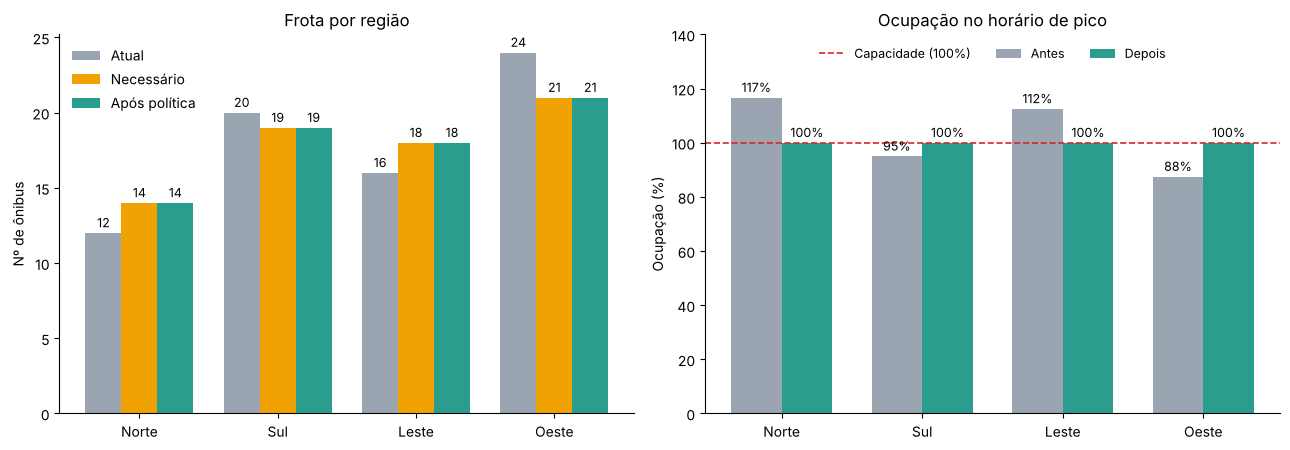

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
pos = np.arange(4); w = 0.26

ax[0].bar(pos - w, x_atual,   w, label="Atual",      color="#9aa5b1")
ax[0].bar(pos,     necessario, w, label="Necessário", color="#f0a202")
ax[0].bar(pos + w, x_dep,     w, label="Após política", color="#2a9d8f")
ax[0].set_xticks(pos); ax[0].set_xticklabels(REGIOES)
ax[0].set_ylabel("Nº de ônibus"); ax[0].set_title("Frota por região")
ax[0].legend(frameon=False)
for cont in ax[0].containers:
    ax[0].bar_label(cont, padding=2, fontsize=9)

ax[1].bar(pos - 0.18, ocupacao_antes * 100, 0.36, label="Antes",  color="#9aa5b1")
ax[1].bar(pos + 0.18, ocupacao_dep * 100,   0.36, label="Depois", color="#2a9d8f")
ax[1].axhline(100, color="#d62828", ls="--", lw=1.2, label="Capacidade (100%)")
ax[1].set_xticks(pos); ax[1].set_xticklabels(REGIOES)
ax[1].set_ylabel("Ocupação (%)"); ax[1].set_title("Ocupação no horário de pico")
ax[1].set_ylim(0, 140)
ax[1].legend(frameon=False, loc="upper center", ncol=3, fontsize=9)
for cont in ax[1].containers:
    ax[1].bar_label(cont, fmt="%.0f%%", padding=2, fontsize=9)

for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

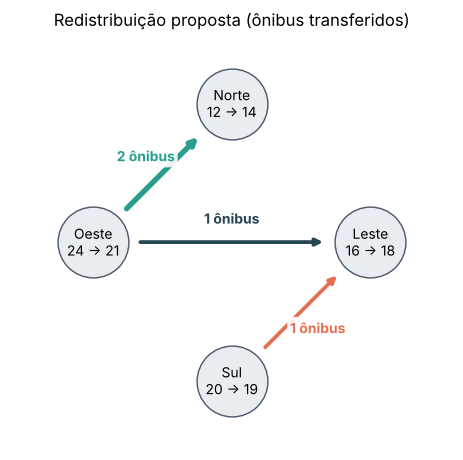

In [15]:
# Mapa dos fluxos de redistribuição (disposição de pontos cardeais)
coords = {"Norte": (0, 1), "Sul": (0, -1), "Leste": (1, 0), "Oeste": (-1, 0)}
fig, ax = plt.subplots(figsize=(6.4, 5.4))
for k, r in enumerate(REGIOES):
    x0, y0 = coords[r]
    ax.scatter(x0, y0, s=2600, color="#e9edf2", edgecolor="#4a5568", zorder=2)
    ax.text(x0, y0, f"{r}\n{x_atual[k]} → {x_dep[k]}", ha="center", va="center", fontsize=10, zorder=3)

cores = {(S_, L_): "#e76f51", (O_, N_): "#2a9d8f", (O_, L_): "#264653"}
deslocamento = {(S_, L_): 0.0, (O_, N_): 0.0, (O_, L_): 0.0}
for (o, d), q in transf.items():
    (xo, yo), (xd, yd) = coords[REGIOES[o]], coords[REGIOES[d]]
    ax.annotate("", xy=(xd, yd), xytext=(xo, yo),
                arrowprops=dict(arrowstyle="-|>", lw=1.5 + 1.2 * q, color=cores[(o, d)],
                                shrinkA=34, shrinkB=34), zorder=1)
    mx, my = (xo + xd) / 2, (yo + yd) / 2
    dx, dy = xd - xo, yd - yo
    nrm = (dx ** 2 + dy ** 2) ** 0.5
    px, py = -dy / nrm, dx / nrm                      # perpendicular à seta
    if px * mx + py * my < 0:                         # empurra o rótulo para fora do centro
        px, py = -px, -py
    ax.text(mx + 0.17 * px, my + 0.17 * py, f"{q} ônibus", color=cores[(o, d)], fontsize=10,
            fontweight="bold", ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.9), zorder=4)
ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.5, 1.5); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Redistribuição proposta (ônibus transferidos)")
plt.show()

## Função geral (reaproveitável no Plantão Enchente)

O mesmo método vale para **qualquer** vetor de demanda (por exemplo, a demanda por evacuação em dia de enchente). A função recebe a frota atual, a demanda e a matriz de custo, e devolve a matriz $A_T$ ótima, com verificação automática das propriedades.

In [16]:
def politica_redistribuicao(x_atual, passageiros, capacidade=40, custo=None):
    # Constrói A_T (frações) que leva a frota atual à necessidade de cada região.
    # Pré-condição: necessidade total == frota total (frota suficiente, mal distribuída).
    x_atual = np.asarray(x_atual, dtype=int)
    need = np.array([math.ceil(p / capacidade) for p in passageiros])
    if need.sum() != x_atual.sum():
        raise ValueError(f"necessidade total ({need.sum()}) difere da frota ({x_atual.sum()}): "
                         "é preciso priorizar regiões (não coberto aqui).")
    saldo = x_atual - need
    don = [i for i in range(len(x_atual)) if saldo[i] > 0]
    rec = [j for j in range(len(x_atual)) if saldo[j] < 0]
    if not don:
        return sp.eye(len(x_atual)), {}
    custo = np.ones((len(x_atual),) * 2) if custo is None else np.asarray(custo)
    par = [(i, j) for i in don for j in rec]
    Aeq = [[1 if p[0] == i else 0 for p in par] for i in don] + \
          [[1 if p[1] == j else 0 for p in par] for j in rec]
    beq = [saldo[i] for i in don] + [-saldo[j] for j in rec]
    r = linprog([custo[i, j] for i, j in par], A_eq=Aeq, b_eq=beq, bounds=[(0, None)] * len(par), method="highs-ds")
    fl = {p: int(round(v)) for p, v in zip(par, r.x) if round(v) > 0}
    M = sp.zeros(len(x_atual), len(x_atual))
    for j in range(len(x_atual)):
        M[j, j] = sp.Rational(int(x_atual[j] - sum(q for (o, d), q in fl.items() if o == j)), int(x_atual[j]))
    for (o, d), q in fl.items():
        M[d, o] = sp.Rational(q, int(x_atual[o]))
    # verificações
    assert all(sum(M[:, j]) == 1 for j in range(len(x_atual)))
    assert all(v >= 0 for v in M)
    assert list(M * sp.Matrix(x_atual.tolist())) == need.tolist()
    return M, fl

M_teste, fl_teste = politica_redistribuicao(x_atual, passageiros, capacidade, custo)
print("A função reproduz a matriz da Etapa 2?", M_teste == A_T)
print("Fluxos:", {f"{REGIOES[o]}->{REGIOES[d]}": q for (o, d), q in fl_teste.items()})

A função reproduz a matriz da Etapa 2? True
Fluxos: {'Sul->Leste': 1, 'Oeste->Norte': 2, 'Oeste->Leste': 1}


---
# Conclusões

1. **Etapa 1.** Os quatro registros consolidados formam um sistema $4\times4$ com $\det A = 3\neq0$. Pelo Teorema de Rouché-Capelli, a solução é **única**: **Norte 12, Sul 20, Leste 16, Oeste 24** (total 72), conferida por três métodos e por substituição nas equações originais.
2. **Diagnóstico.** A demanda exige 14, 19, 18 e 21 ônibus. A frota total basta (72 = 72), mas **Norte e Leste têm déficit de 2** e **Sul e Oeste têm excedente de 1 e 3**: 160 passageiros ficam sem vaga no pico.
3. **Política.** Mover o mínimo de **4 ônibus** (≈ 5,6% da frota), apenas de regiões com excedente para regiões com déficit, escolhendo a combinação de menor custo de deslocamento: Sul→Leste (1), Oeste→Norte (2), Oeste→Leste (1).
4. **Transformação linear.** $T(\mathbf{x})=A_T\mathbf{x}$, com colunas somando 1 e entradas não negativas, o que **prova** a conservação do total e a ausência de alocações negativas para qualquer frota $\mathbf{x}\ge0$. Resultado: ocupação de **100%** em todas as regiões e **0 passageiros sem vaga**.
5. **Limitações.** Dados hipotéticos; frota e demanda estáticas (um único período de pico); sem custos de operação reais; custo de deslocamento baseado em adjacência hipotética; cada ônibus atende apenas a região onde está alocado.

**Extensões para o Plantão Enchente:** trocar `passageiros` pela demanda de evacuação (abrigos, áreas de risco) e `custo` por distâncias reais, alimentando o assistente com o resultado de `politica_redistribuicao`.